In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from scipy import stats
from statsmodels.stats.multitest import multipletests

In [3]:
PROJECT_DIR = Path("/Users/hyuna/OpenNeuro/ds007116")
DERIVED_DIR = PROJECT_DIR / "derived"
RESULTS_DIR = PROJECT_DIR / "results" / "summary_tables"
FIGURE_DIR = PROJECT_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILE = DERIVED_DIR / "clustering_input_z.csv"
CLUSTER_FILE = DERIVED_DIR / "gmm_cluster_assignments_k5.csv"

print("Data:", DATA_FILE.exists())
print("Clusters:", CLUSTER_FILE.exists())

Data: True
Clusters: True


In [4]:
FEATURES = [
    "eswan_adhd_inattention_total",
    "eswan_adhd_hyperactivity_impulsivity_total",
    "bissc_total",
    "bas_total",
    "im_average",
    "em_average",
    "cnb_cptnl_total_sen",
    "cnb_cptnl_total_fp",
    "cnb_edisc_tot",
    "cnb_ddisc_tot",
    "cnb_rdisc_tot",
]

In [5]:
df = pd.read_csv(DATA_FILE)
clusters = pd.read_csv(CLUSTER_FILE)

print("Phenotype data:", df.shape)
print("Cluster assignments:", clusters.shape)

display(clusters.head())

Phenotype data: (92, 13)
Cluster assignments: (92, 4)


,participant_id,session_id,cluster,prob
0,sub-138950,ses-1,4,0.986002
1,sub-19861,ses-1,1,0.997255
2,sub-20125,ses-1,1,0.983757
3,sub-20139,ses-1,1,0.999997
4,sub-20141,ses-1,1,1.000000


In [6]:
analysis_df = df.merge(
    clusters,
    on=["participant_id", "session_id"],
    how="inner",
    validate="one_to_one"
)

print("Merged shape:", analysis_df.shape)
print("Participants:", analysis_df["participant_id"].nunique())

print("\nCluster sizes:")
print(
    analysis_df["cluster"]
    .value_counts()
    .sort_index()
)

Merged shape: (92, 15)
Participants: 92

Cluster sizes:
cluster
0     6
1    41
2     9
3     7
4    29
Name: count, dtype: int64


In [7]:
assert len(analysis_df) == 92
assert analysis_df["participant_id"].nunique() == 92
assert analysis_df[FEATURES].notna().all().all()

In [8]:
profile_z = (
    analysis_df
    .groupby("cluster")[FEATURES]
    .mean()
)

display(profile_z.round(2))

,eswan_adhd_inattention_total,eswan_adhd_hyperactivity_impulsivity_total,bissc_total,bas_total,im_average,em_average,cnb_cptnl_total_sen,cnb_cptnl_total_fp,cnb_edisc_tot,cnb_ddisc_tot,cnb_rdisc_tot
cluster,,,,,,,,,,,
0,0.34,1.13,0.01,-0.20,-0.45,0.47,-2.05,0.38,-0.25,0.36,-0.74
1,-0.19,-0.18,-0.14,0.32,-0.39,-0.43,0.26,-0.23,-0.17,0.06,0.18
2,0.00,-0.21,-0.92,-0.74,0.82,1.00,-0.10,1.82,0.26,-0.73,-0.00
3,-1.95,-1.21,-0.06,1.33,-1.74,-1.83,-1.44,0.45,0.55,0.20,-0.02
4,0.67,0.38,0.50,-0.50,0.81,0.64,0.44,-0.43,0.07,0.02,-0.10


In [9]:
profile_z.to_csv(
    RESULTS_DIR / "phenotype_profiles_k5_z.csv"
)

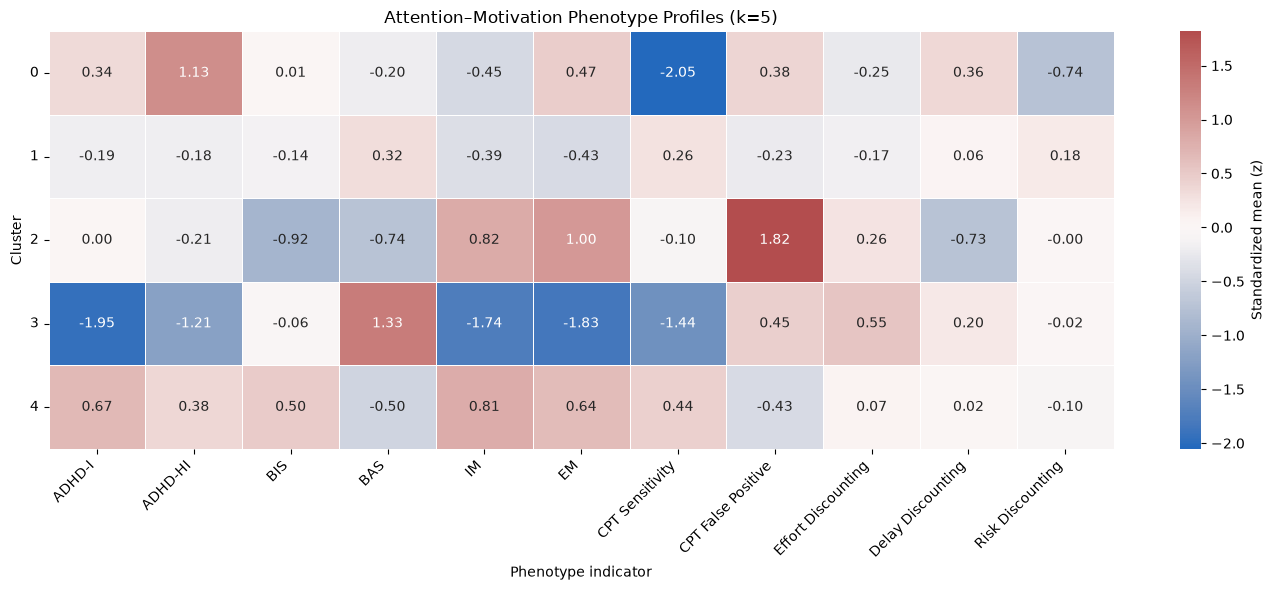

In [10]:
FEATURE_LABELS = {
    "eswan_adhd_inattention_total": "ADHD-I",
    "eswan_adhd_hyperactivity_impulsivity_total": "ADHD-HI",
    "bissc_total": "BIS",
    "bas_total": "BAS",
    "im_average": "IM",
    "em_average": "EM",
    "cnb_cptnl_total_sen": "CPT Sensitivity",
    "cnb_cptnl_total_fp": "CPT False Positive",
    "cnb_edisc_tot": "Effort Discounting",
    "cnb_ddisc_tot": "Delay Discounting",
    "cnb_rdisc_tot": "Risk Discounting",
}

plot_df = profile_z.rename(columns=FEATURE_LABELS)

plt.figure(figsize=(14, 6))

sns.heatmap(
    plot_df,
    annot=True,
    fmt=".2f",
    center=0,
    cmap="vlag",
    linewidths=0.5,
    cbar_kws={"label": "Standardized mean (z)"}
)

plt.title("Attention–Motivation Phenotype Profiles (k=5)")
plt.xlabel("Phenotype indicator")
plt.ylabel("Cluster")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "phenotype_profiles_k5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
display(
    analysis_df.groupby("cluster")[FEATURES]
    .agg(["mean", "std"])
    .round(2)
)

eswan_adhd_inattention_total        \
                                mean   std   
cluster                                      
0                               0.34  0.78   
1                              -0.19  0.66   
2                               0.00  1.11   
3                              -1.95  0.76   
4                               0.67  0.76   

        eswan_adhd_hyperactivity_impulsivity_total       bissc_total        \
                                              mean   std        mean   std   
cluster                                                                      
0                                             1.13  0.83        0.01  0.96   
1                                            -0.18  0.73       -0.14  0.86   
2                                            -0.21  0.92       -0.92  0.96   
3                                            -1.21  1.56       -0.06  1.11   
4                                             0.38  0.89        0.50  0.99   

        bas_total       im_average        ... cnb_cptnl_total_sen        \
             mean   std       mean   std  ...                mean   std   
cluster                                   ...                             
0           -0.20  0.52      -0.45  0.84  ...               -2.05  1.93   
1            0.32  0.89      -0.39  0.67  ...                0.26  0.42   
2           -0.74  0.80       0.82  0.67  ...               -0.10  0.65   
3            1.33  1.69      -1.74  0.59  ...               -1.44  1.16   
4           -0.50  0.53       0.81  0.62  ...                0.44  0.48   

        cnb_cptnl_total_fp       cnb_edisc_tot       cnb_ddisc_tot        \
                      mean   std          mean   std          mean   std   
cluster                                                                    
0                     0.38  1.29         -0.25  1.03          0.36  0.60   
1                    -0.23  0.54         -0.17  0.79          0.06  0.99   
2                     1.82  1.63          0.26  1.11         -0.73  0.58   
3                     0.45  1.13          0.55  1.62          0.20  0.90   
4                    -0.43  0.36          0.07  1.07          0.02  1.16   

        cnb_rdisc_tot        
                 mean   std  
cluster                      
0               -0.74  1.24  
1                0.18  1.01  
2               -0.00  1.14  
3               -0.02  0.50  
4               -0.10  0.98  

[5 rows x 22 columns]

In [12]:
desc_z = (
    analysis_df
    .groupby("cluster")[FEATURES]
    .agg(["mean", "std"])
)

desc_z.to_csv(
    RESULTS_DIR / "phenotype_descriptives_k5_z.csv"
)

In [13]:
def eta_squared(groups):
    all_values = np.concatenate(groups)
    grand_mean = np.mean(all_values)

    ss_between = sum(
        len(g) * (np.mean(g) - grand_mean) ** 2
        for g in groups
    )

    ss_total = np.sum(
        (all_values - grand_mean) ** 2
    )

    return ss_between / ss_total


def epsilon_squared_kw(H, n, k):
    return (H - k + 1) / (n - k)

In [14]:
results = []

cluster_ids = sorted(
    analysis_df["cluster"].unique()
)

for feature in FEATURES:

    groups = [
        analysis_df.loc[
            analysis_df["cluster"] == c,
            feature
        ].dropna().values
        for c in cluster_ids
    ]

    # One-way ANOVA
    F, p_anova = stats.f_oneway(*groups)

    eta2 = eta_squared(groups)

    # Kruskal-Wallis
    H, p_kw = stats.kruskal(*groups)

    eps2 = epsilon_squared_kw(
        H,
        n=sum(len(g) for g in groups),
        k=len(groups)
    )

    results.append({
        "feature": feature,
        "F": F,
        "p_anova": p_anova,
        "eta_squared": eta2,
        "H": H,
        "p_kw": p_kw,
        "epsilon_squared": eps2
    })

characterization = pd.DataFrame(results)

In [15]:
characterization["p_anova_fdr"] = multipletests(
    characterization["p_anova"],
    method="fdr_bh"
)[1]

characterization["p_kw_fdr"] = multipletests(
    characterization["p_kw"],
    method="fdr_bh"
)[1]

In [16]:
characterization = (
    characterization
    .sort_values(
        "eta_squared",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    characterization.round(4)
)

,feature,F,p_anova,eta_squared,H,p_kw,epsilon_squared,p_anova_fdr,p_kw_fdr
0,im_average,30.8128,0.0000,0.5862,51.1855,0.0000,0.5424,0.0000,0.0000
1,em_average,30.3278,0.0000,0.5824,50.2888,0.0000,0.5321,0.0000,0.0000
2,cnb_cptnl_total_sen,24.0487,0.0000,0.5251,32.5254,0.0000,0.3279,0.0000,0.0000
3,eswan_adhd_inattention_total,18.0834,0.0000,0.4540,33.8020,0.0000,0.3426,0.0000,0.0000
4,cnb_cptnl_total_fp,16.3448,0.0000,0.4291,22.7712,0.0001,0.2158,0.0000,0.0003
5,bas_total,9.9331,0.0000,0.3135,25.1911,0.0000,0.2436,0.0000,0.0001
6,eswan_adhd_hyperactivity_impulsivity_total,7.5254,0.0000,0.2571,21.5089,0.0003,0.2013,0.0000,0.0004
7,bissc_total,4.4723,0.0025,0.1706,13.2050,0.0103,0.1058,0.0034,0.0142
8,cnb_ddisc_tot,1.5232,0.2025,0.0655,9.4435,0.0509,0.0626,0.2475,0.0622
9,cnb_rdisc_tot,1.2180,0.3091,0.0530,5.7377,0.2196,0.0200,0.3400,0.2416


In [17]:
characterization.to_csv(
    RESULTS_DIR / "phenotype_characterization_k5.csv",
    index=False
)

In [18]:
characterization["indicator"] = (
    characterization["feature"]
    .map(FEATURE_LABELS)
)

display(
    characterization[
        [
            "indicator",
            "F",
            "p_anova_fdr",
            "eta_squared",
            "H",
            "p_kw_fdr",
            "epsilon_squared"
        ]
    ].round(3)
)

,indicator,F,p_anova_fdr,eta_squared,H,p_kw_fdr,epsilon_squared
0,IM,30.813,0.000,0.586,51.186,0.000,0.542
1,EM,30.328,0.000,0.582,50.289,0.000,0.532
2,CPT Sensitivity,24.049,0.000,0.525,32.525,0.000,0.328
3,ADHD-I,18.083,0.000,0.454,33.802,0.000,0.343
4,CPT False Positive,16.345,0.000,0.429,22.771,0.000,0.216
5,BAS,9.933,0.000,0.314,25.191,0.000,0.244
6,ADHD-HI,7.525,0.000,0.257,21.509,0.000,0.201
7,BIS,4.472,0.003,0.171,13.205,0.014,0.106
8,Delay Discounting,1.523,0.247,0.065,9.444,0.062,0.063
9,Risk Discounting,1.218,0.340,0.053,5.738,0.242,0.020


In [19]:
posterior_summary = (
    analysis_df["prob"]
    .describe()
)

display(posterior_summary)

count    92.000000
mean      0.990769
std       0.031488
min       0.754670
25%       0.997410
50%       0.999995
75%       1.000000
max       1.000000
Name: prob, dtype: float64

In [20]:
posterior_by_cluster = (
    analysis_df
    .groupby("cluster")["prob"]
    .agg(["count", "mean", "std", "min", "median"])
)

display(
    posterior_by_cluster.round(3)
)

,count,mean,std,min,median
cluster,,,,,
0,6,1.000,0.000,1.000,1.0
1,41,0.989,0.039,0.755,1.0
2,9,1.000,0.000,1.000,1.0
3,7,1.000,0.000,1.000,1.0
4,29,0.986,0.031,0.876,1.0


In [21]:
posterior_by_cluster.to_csv(
    RESULTS_DIR / "posterior_probability_by_cluster_k5.csv"
)

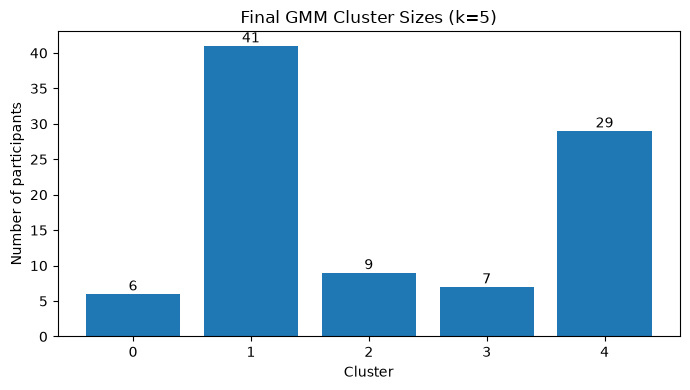

In [22]:
cluster_sizes = (
    analysis_df["cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 4))

plt.bar(
    cluster_sizes.index.astype(str),
    cluster_sizes.values
)

plt.xlabel("Cluster")
plt.ylabel("Number of participants")
plt.title("Final GMM Cluster Sizes (k=5)")

for i, n in enumerate(cluster_sizes.values):
    plt.text(
        i,
        n + 0.5,
        str(n),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "cluster_sizes_k5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
## Summary

The five-component solution showed substantial differentiation
across both self-report and behavioral attention–motivation
indicators.

The strongest differentiation was observed for IM and EM,
followed by CPT sensitivity, ADHD inattention, and CPT false
positives. BAS and ADHD hyperactivity/impulsivity also contributed
substantially to phenotype differentiation, whereas effort, delay,
and risk discounting showed relatively little differentiation
across clusters.

The resulting profiles were not organized along a simple
low-to-high symptom severity continuum. Instead, self-reported
attention/motivation characteristics and behavioral CPT
performance showed distinct combinations across phenotypes.

Because these variables were used to derive the GMM solution,
these comparisons characterize the identified phenotypes rather
than provide independent validation.